<a href="https://colab.research.google.com/github/hilalkaynarcali/goruntu-isleme/blob/main/ters_DFT_ZNCC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim

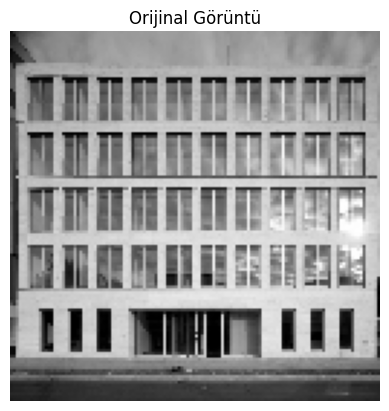

In [3]:
resim = cv2.imread("image09.jpeg", cv2.IMREAD_GRAYSCALE)

resim = cv2.resize(resim, (128, 128))

plt.imshow(resim, cmap="gray")
plt.title("Orijinal Görüntü")
plt.axis("off")
plt.show()

In [4]:
def gauss_gurultusu(goruntu, sigma):
    gurultu = np.random.normal(0, sigma, goruntu.shape)
    sonuc = goruntu.astype(float) + gurultu
    return np.clip(sonuc, 0, 255).astype(np.uint8)


def salt_pepper_gurultusu(goruntu, oran):
    if not 0 <= oran <= 1:
        raise ValueError("Oran 0 ile 1 arasında olmalıdır!")

    sonuc = goruntu.copy()
    adet = int(sonuc.size * oran)

    indeksler = np.random.choice(
        sonuc.size, adet, replace=False
    )

    duz = sonuc.ravel()
    yari = adet // 2

    duz[indeksler[:yari]] = 0
    duz[indeksler[yari:]] = 255

    return sonuc

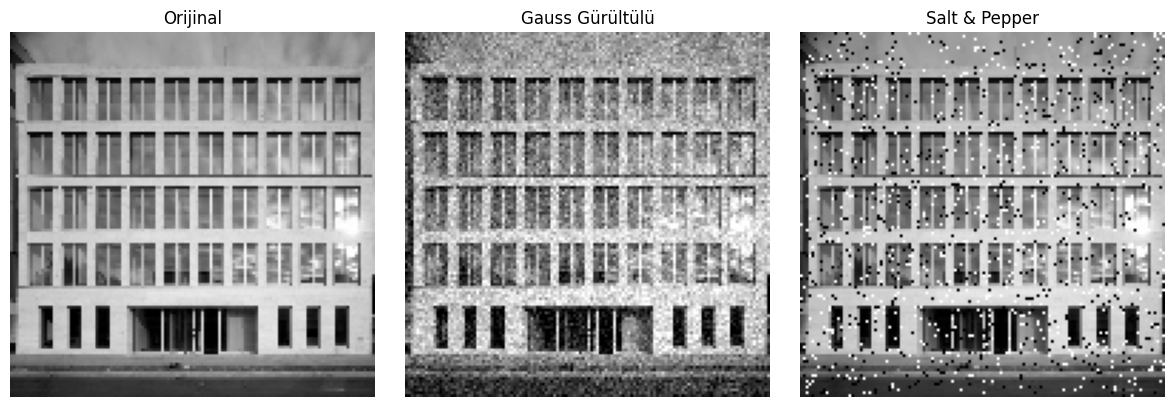

In [5]:
np.random.seed(42)

gauss_resim = gauss_gurultusu(resim, sigma=25)
sp_resim = salt_pepper_gurultusu(resim, oran=0.08)

plt.figure(figsize=(12, 4))

for i, (goruntu, baslik) in enumerate([
    (resim, "Orijinal"),
    (gauss_resim, "Gauss Gürültülü"),
    (sp_resim, "Salt & Pepper")
]):
    plt.subplot(1, 3, i + 1)
    plt.imshow(goruntu, cmap="gray", vmin=0, vmax=255)
    plt.title(baslik)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
def dft2_hesapla(goruntu):
    M, N = goruntu.shape

    m = np.arange(M)
    n = np.arange(N)

    W1 = np.exp(-2j * np.pi * np.outer(m, m) / M)
    W2 = np.exp(-2j * np.pi * np.outer(n, n) / N)

    return W1 @ goruntu @ W2.T


def ters_dft2(harmonik):
    M, N = harmonik.shape

    m = np.arange(M)
    n = np.arange(N)

    W1 = np.exp(2j * np.pi * np.outer(m, m) / M)
    W2 = np.exp(2j * np.pi * np.outer(n, n) / N)

    sonuc = (W1 @ harmonik @ W2.T) / (M * N)

    return sonuc.real

In [7]:
def frekans_filtresi(harmonik, kesim=0.18):
    M, N = harmonik.shape

    fy = np.fft.fftfreq(M)[:, None]
    fx = np.fft.fftfreq(N)[None, :]

    maske = np.exp(
        -(fx**2 + fy**2) / (2 * kesim**2)
    )

    return harmonik * maske

In [9]:
H_gauss = dft2_hesapla(gauss_resim)
H_sp = dft2_hesapla(sp_resim)

gauss_idft = ters_dft2(H_gauss)
sp_idft = ters_dft2(H_sp)

gauss_filtreli_H = frekans_filtresi(H_gauss)
sp_filtreli_H = frekans_filtresi(H_sp)

gauss_temiz = np.clip(
    ters_dft2(gauss_filtreli_H), 0, 255
)

sp_temiz = np.clip(
    ters_dft2(sp_filtreli_H), 0, 255
)

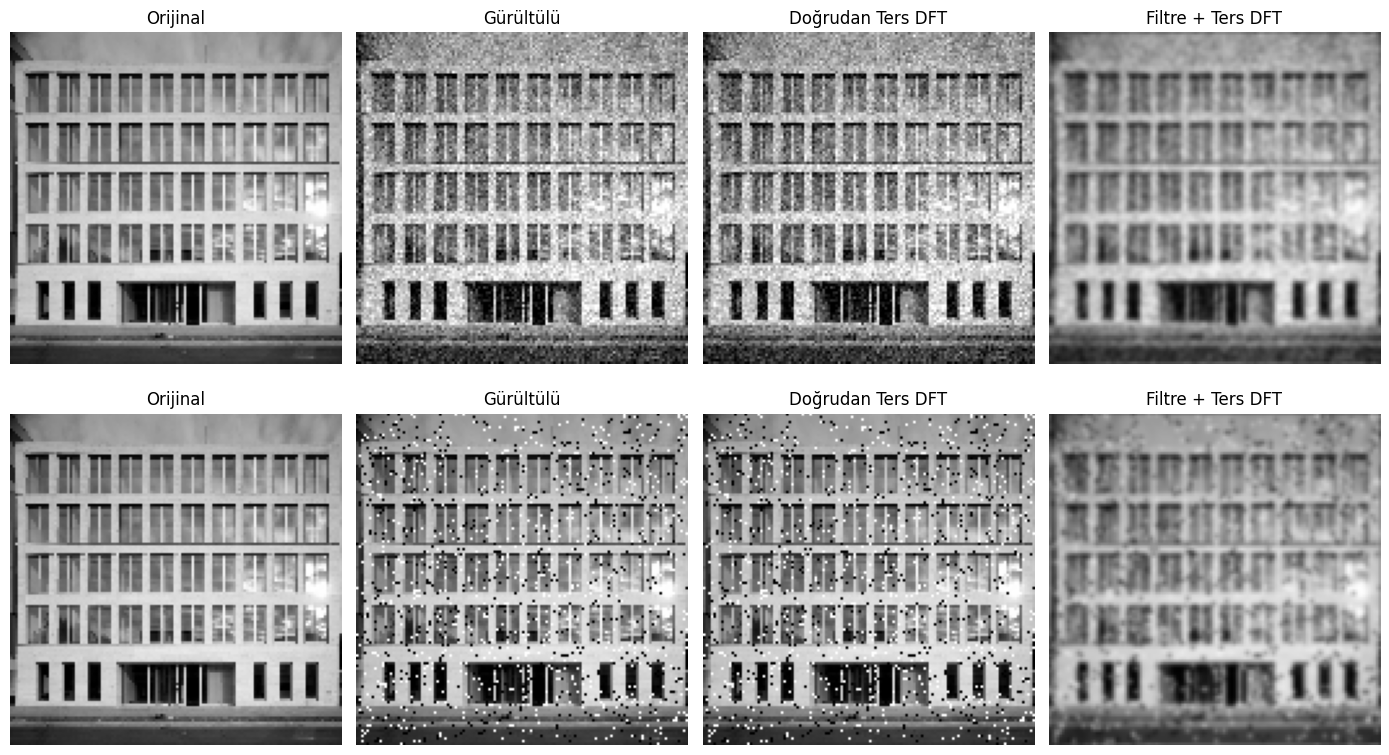

In [10]:
plt.figure(figsize=(14, 8))

satirlar = [
    [resim, gauss_resim, gauss_idft, gauss_temiz],
    [resim, sp_resim, sp_idft, sp_temiz]
]

basliklar = [
    "Orijinal",
    "Gürültülü",
    "Doğrudan Ters DFT",
    "Filtre + Ters DFT"
]

for i in range(2):
    for j in range(4):
        plt.subplot(2, 4, i * 4 + j + 1)
        plt.imshow(
            satirlar[i][j],
            cmap="gray",
            vmin=0,
            vmax=255
        )
        plt.title(basliklar[j])
        plt.axis("off")

plt.tight_layout()
plt.savefig("odev39_idft_sonuclar.png", dpi=200)
plt.show()

In [11]:
def zncc(goruntu1, goruntu2):
    a = goruntu1.astype(float).ravel()
    b = goruntu2.astype(float).ravel()

    a = a - np.mean(a)
    b = b - np.mean(b)

    pay = np.sum(a * b)

    payda = np.sqrt(
        np.sum(a**2) * np.sum(b**2)
    )

    if payda == 0:
        return np.nan

    return pay / payda

In [12]:
veriler = {
    "Gauss": (gauss_resim, gauss_idft, gauss_temiz),
    "Salt & Pepper": (sp_resim, sp_idft, sp_temiz)
}

for ad, (gurultulu, idft, filtreli) in veriler.items():
    print(ad)

    print(
        "Gürültülü ZNCC:",
        round(zncc(resim, gurultulu), 4)
    )

    print(
        "Doğrudan IDFT ZNCC:",
        round(zncc(resim, idft), 4)
    )

    print(
        "Filtreli IDFT ZNCC:",
        round(zncc(resim, filtreli), 4)
    )

    print()

Gauss
Gürültülü ZNCC: 0.9285
Doğrudan IDFT ZNCC: 0.9285
Filtreli IDFT ZNCC: 0.9136

Salt & Pepper
Gürültülü ZNCC: 0.8182
Doğrudan IDFT ZNCC: 0.8182
Filtreli IDFT ZNCC: 0.8885



In [13]:
def metrikler(orijinal, goruntu):
    a = orijinal.astype(float)
    b = goruntu.astype(float)

    mse = np.mean((a - b)**2)
    rmse = np.sqrt(mse)

    psnr = (
        10 * np.log10(255**2 / mse)
        if mse > 0 else float("inf")
    )

    ssim_degeri = ssim(a, b, data_range=255)

    return rmse, psnr, ssim_degeri


for ad, (gurultulu, idft, filtreli) in veriler.items():
    print(ad)

    for isim, goruntu in [
        ("Gürültülü", gurultulu),
        ("Filtreli", filtreli)
    ]:
        rmse, psnr, ssim_sonuc = metrikler(resim, goruntu)

        print(
            f"{isim}: RMSE={rmse:.3f}, "
            f"PSNR={psnr:.2f} dB, "
            f"SSIM={ssim_sonuc:.4f}"
        )

    print()

Gauss
Gürültülü: RMSE=24.388, PSNR=20.39 dB, SSIM=0.7899
Filtreli: RMSE=26.351, PSNR=19.71 dB, SSIM=0.7510

Salt & Pepper
Gürültülü: RMSE=40.319, PSNR=16.02 dB, SSIM=0.6596
Filtreli: RMSE=29.549, PSNR=18.72 dB, SSIM=0.6926

